## Sampling Space: DIY Spatial Room Impulse Response Capture for Creative Applications
### *AES Show Nashville, 2026*


The following notebook accompanies the above workshop on conducting Spatial Room Impulse Response (SRIR) measurements for creative applications. It includes simulated data for the SRIR recording and processing pipeline. Real world measurement scenarios require the appropriate loudspeaker output, microphone array (spaced array, binaural, ambisonic), and careful equipment calibration.

### Contents:

1. Types of test signal
2. Exponential Sine Sweep (ESS)
3. Sweep generation
4. Simulated Example
5. Deconvolution Methods
6. Harmonic Distortion Separation
7. From Mono RIR to Simulated B-format SRIR

### How to use this notebook in the workshop:

- Run the notebook once from top to bottom using **Runtime -> Run all** in the Colab menu bar. This will execute all the code in the notebook. Beginning in Section 3 you will find **Participant Cells** that you can use to experiment with different signal parameters.These cells can be run independently by clicking the circled "play" button in the upper left-hand corner of the cell without affecting code cells before or after.

- All sections are collapsable by using the chevron symbol to the left of the section number for navigation.

- There are several optional sections that demonstrate more underlying theory for the curious reader.


# 1. Types of test signal

Four common types of test signals used for acoustic impulse response measurement:

- Maximum-length sequence (MLS)
- Inverse repeated sequence (IRS)
- Time-stretched pulse (TSP)
- Exponential sine sweep (ESS)

While each test signal has pros/cons depending on the use-case, **this demonstration will focus on the ESS.**

MLS and IRS are deterministic, pseudo-random sequences with a flat, noise-like spectrum and very efficient deconvolution, but they are sensitive to nonlinearity and time-variance (distortion products show up as spurious spikes smeared across the whole impulse response). IRS, which is built from an MLS, cancels even-order distortion. A time-stretched pulse is a flat-spectrum sweep, typically with linear frequency progression; it compresses well but has no way to separate distortion from the linear response. The ESS is the logarithmic member of the sweep family, and this is what makes harmonic distortion separable (see Section 6).

# 2. Exponential Sine Sweep (ESS)

The ESS is a common excitation signal for room acoustic measurement today. The benefits of ESS over other generated signals are:

- Separation of nonlinear harmonic distortion elements and linear impulse response
- Excellent signal-to-noise (SNR) ratio: the energy is spread over the whole sweep (longer sweep, more SNR: +3 dB per doubling of duration), the pink (-3 dB/oct) spectrum puts more energy at low frequencies where ambient noise is often strongest, and the constant-amplitude sinusoid allows for the loudspeaker to be driven hard without clipping

A quiet, unoccupied room will give the best results, but the ESS tolerates moderate background noise well.

Equation:

$$
x(t) = \sin\left[
\frac{w_1 T}{\ln(w_2/w_1)}
\left(
e^{\frac{t}{T}\ln(w_2/w_1)} - 1
\right)
\right]
$$

where:
- $w_1$ = initial frequency (radians/sec)
- $w_2$ = final frequency (radians/sec)
- $T$ = sweep duration (seconds)
- $t$ = independent time variable

# 3. Sweep Generation

The following code outlines the process of generating an ESS signal from scratch beginning with the following user-chosen parameters:

- Sample rate (Hz)
- Sweep duration (seconds)
- Start frequency (Hz)
- End frequency (Hz)

In [ ]:
# Imports

import numpy as np
from scipy import signal
import librosa
import librosa.display
import soundfile as sf
from IPython.display import Audio, display
import matplotlib.pyplot as plt

## Participant Cell 1 — Set sweep parameters

These are the main values you can experiment with: sample rate, sweep duration, and start/end frequencies. For the workshop, the defaults are a 5-second sweep from 20 Hz to 20 kHz at 48 kHz sampling rate.

In [ ]:
# Test signal parameters

fs = 48000    # Sample rate (Hz)
T  = 5        # Sweep duration (sec)
f1 = 20       # Start frequency (Hz)
f2 = 20000    # End frequency (Hz)

w1 = 2 * np.pi * f1   # Hz -> radians
w2 = 2 * np.pi * f2

N = int(T * fs)       # Number of samples in sweep
t = np.arange(N)/fs   # Time vector (seconds)
Ts = 1 / fs           # Sample period

print(f"Number of samples in sweep: {N}")
print(f"Sampling interval: {Ts:.3e} seconds")
print(f"Sweep duration: {N / fs} seconds")

Number of samples in sweep: 240000
Sampling interval: 2.083e-05 seconds
Sweep duration: 5.0 seconds


## Participant Cell 2 — Generate and listen to the ESS

Run this cell to create the exponential sine sweep, plot its waveform, and listen to it. **Turn your volume down before playback.**

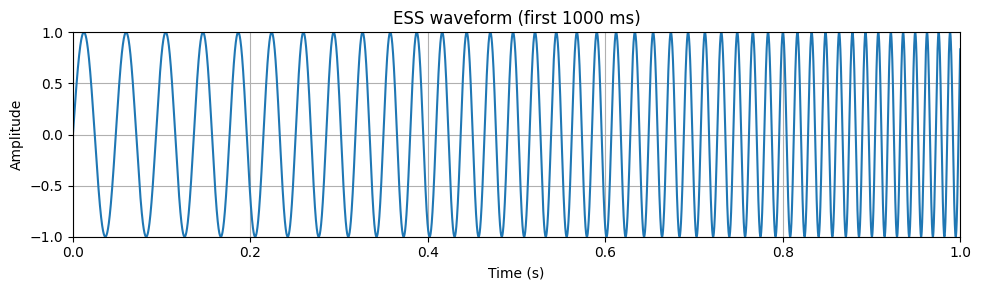

In [ ]:
# Implement ESS and plot

# ESS algorithm
ESS = np.sin((w1*T)/np.log(w2/w1) * (np.exp((t/T)*np.log(w2/w1)) - 1))

# Plot
plt.figure(figsize=(10, 3))
plt.plot(t, ESS)
plt.xlim(0, 1)
plt.ylim(-1, 1)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("ESS waveform (first 1000 ms)")
plt.grid(True)
plt.tight_layout()
plt.show()

# CAUTION: TURN VOLUME DOWN FIRST. This is a full-scale 20 Hz - 20 kHz sweep,
# and Audio() auto-normalizes, so quiet signals will also play back loud.
display(Audio(ESS, rate=fs))

## Optional: Instantaneous Frequency and Spectral Representation

The instantaneous frequency is not needed to conduct successful SRIR measurements, but can be a helpful concept for signal visualization and understanding:

$$inst\_freq = \frac{1}{2\pi}\frac{d\phi}{dt} = \frac{1}{2\pi}\left[w_1 \cdot e^{t \cdot \frac{\ln(w_2 / w_1)}{T}}\right]$$

for our ESS signal  $x(t) = sin(\phi)$.

The code below computes $inst\_freq$ in Hz not radians/sec for ease of use.

It is also where the distortion-separation property of the ESS comes from (Section 6): a $k$-th harmonic generated by a nonlinearity at time $t$ has frequency $k\cdot inst\_freq(t)$, which the sweep itself only reaches $T\ln k/\ln(w_2/w_1)$ seconds later. After deconvolution, the $k$-th harmonic therefore appears that long *before* the linear impulse response.


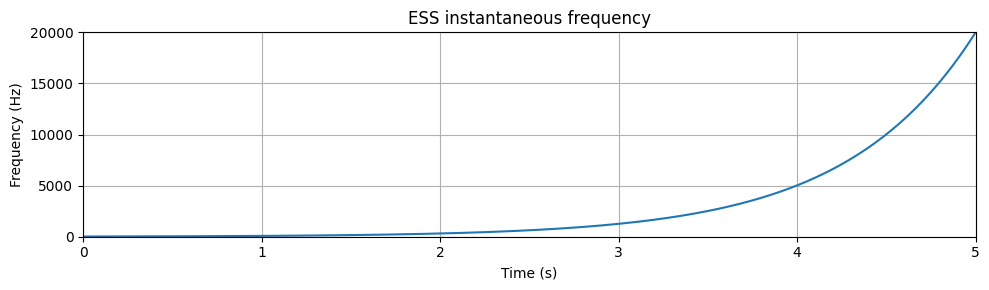

In [ ]:
# Calculate instantaneous frequency

inst_freq = (1 / (2 * np.pi)) * (w1 * np.exp(t * (np.log(w2 / w1)) / T))

# Plot
plt.figure(figsize=(10, 3))
plt.plot(t, inst_freq)
plt.xlim(0, 5)
plt.ylim(0, 20000)
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.title("ESS instantaneous frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

This can similarly be viewed in the time-frequency domain as a spectrogram with a linear frequency scale:

stft shape=(1025, 469)


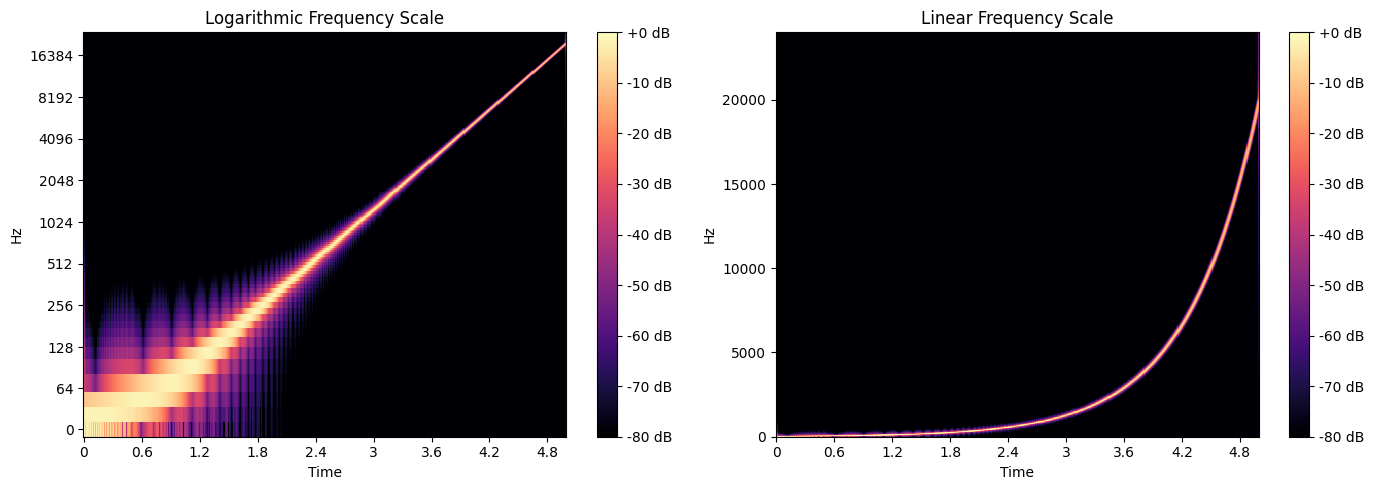

In [ ]:
# Take STFT of sine sweep
stft = librosa.stft(ESS)
print(f"stft shape={stft.shape}")

# Convert complex STFT to decibel-scaled magnitude spectrogram
stft_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Logarithmic frequency scale
img1 = librosa.display.specshow(stft_db, sr=fs, x_axis="time", y_axis='log', ax=ax1)
fig.colorbar(img1, ax=ax1, format="%+2.0f dB")
ax1.set_title("Logarithmic Frequency Scale")

# Linear frequency scale (hz)
img2 = librosa.display.specshow(stft_db, sr=fs, x_axis="time", y_axis="hz", ax=ax2)
fig.colorbar(img2, ax=ax2, format="%+2.0f dB")
ax2.set_title("Linear Frequency Scale")

plt.tight_layout()
plt.show()

# 4. Simulated Example

RIRs can be modeled as linear, time-invariant (LTI) systems in the form:

$$ y[n] = x[n] *  h[n] + v[n] $$

where:
- $y[n]$ = measured signal
- $x[n]$ = excitation signal (ESS)
- $h[n]$ = RIR
- $v[n]$ = background noise picked up by the microphone
- $(*)$  denotes linear convolution.

We use full convolution here so the response tail is not cropped, and we add a small amount of noise so the simulation behaves more like a real measurement.

This example demonstrates the **direct sound**, two **early reflections**, and a **late reverb tail** generated with damped white noise.

## Participant Cell 3 - Create the simulated room response and recording

The next two cells construct a known room impulse response (direct sound, early reflections, and a decaying tail), then simulate the sweep recorded through that room with added noise.

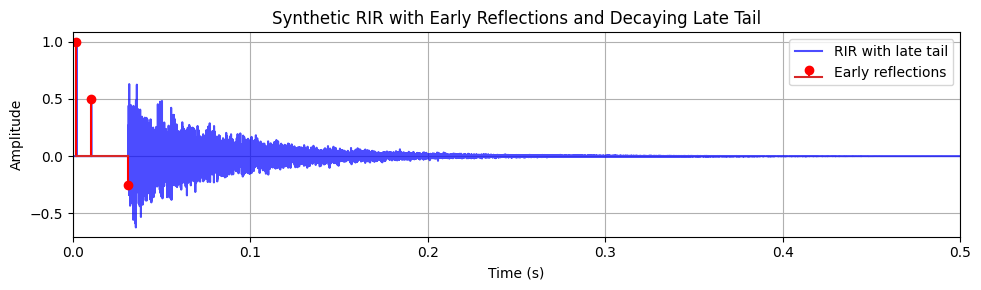

In [ ]:
# Set RIR duration and create sample vector
rir_duration = 0.5  # seconds
rir_length = int(rir_duration * fs)

# Initialize the RIR and add the direct path and early reflections
true_rir = np.zeros(rir_length)
true_rir[100] = 1.0             # Direct
true_rir[500] = 0.5             # Reflection 1
true_rir[1500] = -0.25          # Reflection 2

# Generate an exponentially decaying late reverberation tail
rt60 = 0.4                      # Decay time for a 60 dB reduction (seconds)
tail_start_sample = 1501        # Start immediately after the last reflection
alpha = -np.log(0.001) / rt60   # Damping coefficient

tail_length = rir_length - tail_start_sample
t_tail = np.arange(tail_length) / fs
decay_envelope = np.exp(-alpha * t_tail)

# Scale reproducible noise by the decay envelope
np.random.seed(514)
noise_tail = np.random.randn(tail_length) * decay_envelope * 0.2
true_rir[tail_start_sample:] += noise_tail

# Organize RIR samples in time
rir_time = np.arange(rir_length) / fs


plt.figure(figsize=(10, 3))
plt.plot(rir_time, true_rir, color='b', alpha=0.7, label='RIR with late tail')
plt.xlim(0, 0.5)
plt.stem([100/fs, 500/fs, 1500/fs], [1.0, 0.5, -0.25], linefmt='r-', label='Early reflections')
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Synthetic RIR with Early Reflections and Decaying Late Tail")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

display(Audio(true_rir, rate=fs))

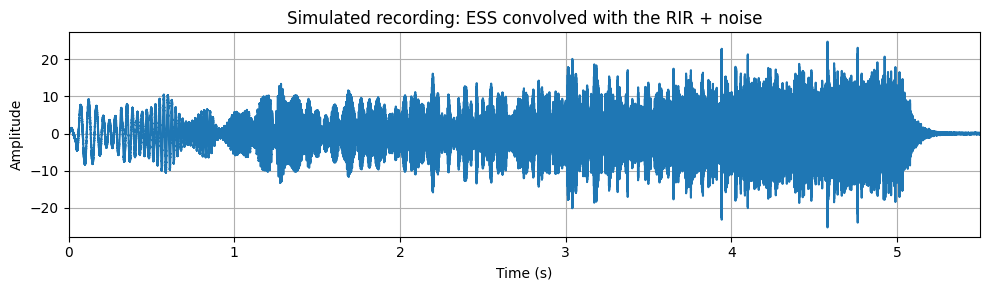

In [ ]:
# Create clean simulated recording (no noise)
recording_clean = signal.fftconvolve(ESS, true_rir, mode="full")

# Add simulated microphone/background noise
rng = np.random.default_rng(514)
noise = 0.075 * rng.standard_normal(len(recording_clean))
recording_noisy = recording_clean + noise
recording_time = np.arange(len(recording_noisy)) / fs

plt.figure(figsize=(10, 3))
plt.plot(recording_time, recording_noisy)
plt.xlim(0, recording_time[-1])
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title(f"Simulated recording: ESS convolved with the RIR + noise")
plt.grid(True)
plt.tight_layout()
plt.show()

# VOLUME WARNING (again)
display(Audio(recording_noisy, rate=fs))

# 5. Deconvolution Methods

## Method 1 - ESS Inverse Filtering

We apply an inverse filter to the recorded sweep response to remove the sweep's influence and recover the room impulse response. This produces a time-domain signal that can be inspected directly.

Equation:

$$ \hat h[n] = y[n] * h_{\mathrm{inv}}[n] $$

$$ h_{\mathrm{inv}}[n] = \beta x[N-1-n]e^{-nT_s\ln(w_2/w_1)/T}$$

where:

- $N$ = number of samples in the sweep
- $T_s = 1/f_s$ = sampling period
- $T$ = sweep duration
- $h_{\mathrm{inv}}[n]$ = The time-reversed and exponentially decaying filter used to deconvolve the ESS.
- $\beta$ = Scaling constant that makes the peak of the compressed sweep (ESS convolved with its own inverse filter) equal to 1, so the deconvolution does not boost/attenuate the overall amplitude of the recovered RIR

Note:
- **sweep_compressed**: The result of convolving the original ESS with its inverse filter. This acts as a band-limited Dirac delta function (a single sharp peak)
- **peak_index**: The index of the maximum amplitude in the compressed sweep. It equals $N_x-1$ and marks $t=0$ of the measurement chain: anything the deconvolution places *after* this index is the (linear) impulse response, including any latency and propagation delay

### Participant Cell 4 — Run Method 1: Deconvolution with inverse filter

This section constructs and inspects the inverse filter used by Method 1. The pulse-compression and spectrogram plots are optional details. The visible participant cell below applies the prepared filter to the simulated recording.

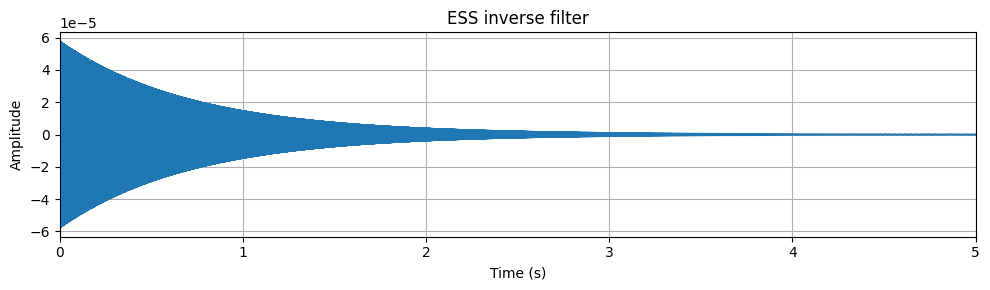

In [ ]:
# Build the exponentially weighted, time-reversed ESS inverse filter.
inverse_filter = ESS[::-1] * np.exp(-t * np.log(w2 / w1) / T)

# Normalize the sweep/inverse-filter peak to one.
sweep_compressed = signal.fftconvolve(ESS, inverse_filter, mode="full")
peak_index = np.argmax(np.abs(sweep_compressed))
inverse_filter = inverse_filter / sweep_compressed[peak_index]

# Plot
plt.figure(figsize=(10, 3))
plt.plot(np.arange(len(inverse_filter)) / fs, inverse_filter)
plt.xlim(0, 5)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("ESS inverse filter")
plt.grid(True)
plt.tight_layout()
plt.show()

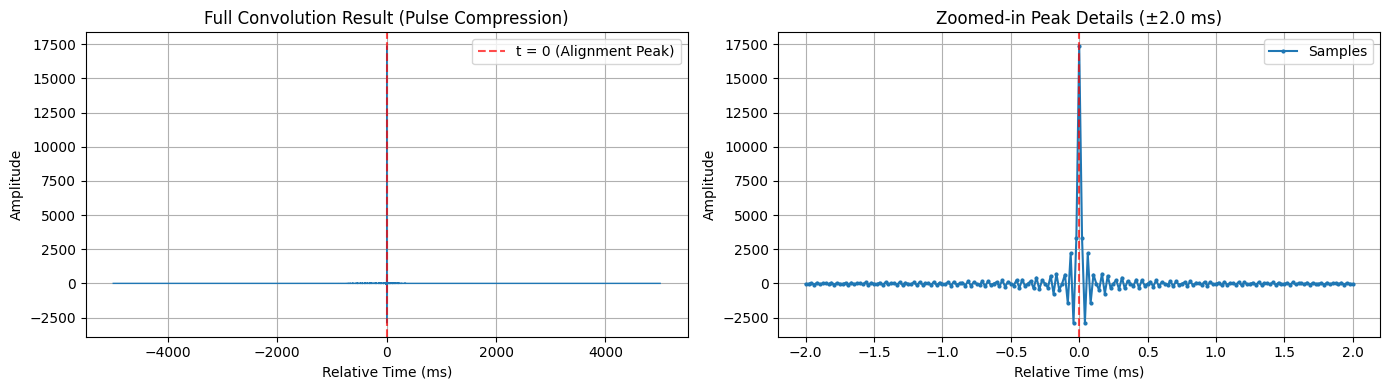

In [ ]:
# Calculate relative time in milliseconds centered at the peak
t_rel_ms = (np.arange(len(sweep_compressed)) - peak_index) / fs * 1000

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Full view showing silence around peak
ax1.plot(t_rel_ms, sweep_compressed, color='C0', linewidth=1)
ax1.axvline(0, color='r', linestyle='--', alpha=0.7, label='t = 0 (Alignment Peak)')
ax1.set_xlabel("Relative Time (ms)")
ax1.set_ylabel("Amplitude")
ax1.set_title("Full Convolution Result (Pulse Compression)")
ax1.grid(True)
ax1.legend()

# Zoomed-in view showing the band-limited sinc-like peak structure
zoom_limit_ms = 2.0  # zoom window (+/- 2 ms around peak)
zoom_mask = (t_rel_ms >= -zoom_limit_ms) & (t_rel_ms <= zoom_limit_ms)

ax2.plot(t_rel_ms[zoom_mask], sweep_compressed[zoom_mask], color='C0', marker='.', markersize=4, label='Samples')
ax2.axvline(0, color='r', linestyle='--', alpha=0.7)
ax2.set_xlabel("Relative Time (ms)")
ax2.set_ylabel("Amplitude")
ax2.set_title(f"Zoomed-in Peak Details (±{zoom_limit_ms} ms)")
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()

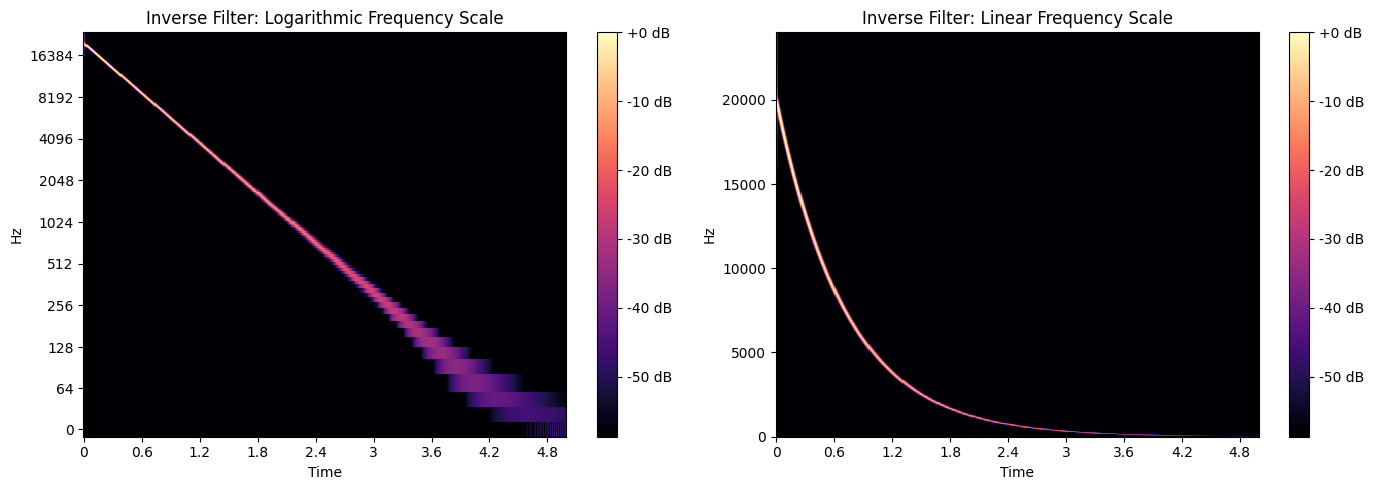

In [ ]:
# Calculate the STFT of the inverse filter
stft_inv = librosa.stft(inverse_filter)

# Convert complex STFT to decibel-scaled magnitude spectrogram
# Use ref=np.max for relative scaling, but note that the inverse filter has much lower overall energy
stft_inv_db = librosa.amplitude_to_db(np.abs(stft_inv), ref=np.max)

# Plot spectrograms
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Logarithmic frequency scale
img1 = librosa.display.specshow(stft_inv_db, sr=fs, x_axis="time", y_axis='log', ax=ax1)
fig.colorbar(img1, ax=ax1, format="%+2.0f dB")
ax1.set_title("Inverse Filter: Logarithmic Frequency Scale")

# Linear frequency scale (Hz)
img2 = librosa.display.specshow(stft_inv_db, sr=fs, x_axis="time", y_axis="hz", ax=ax2)
fig.colorbar(img2, ax=ax2, format="%+2.0f dB")
ax2.set_title("Inverse Filter: Linear Frequency Scale")

plt.tight_layout()
plt.show()

Detected direct-path index: 100 (true if = 100)


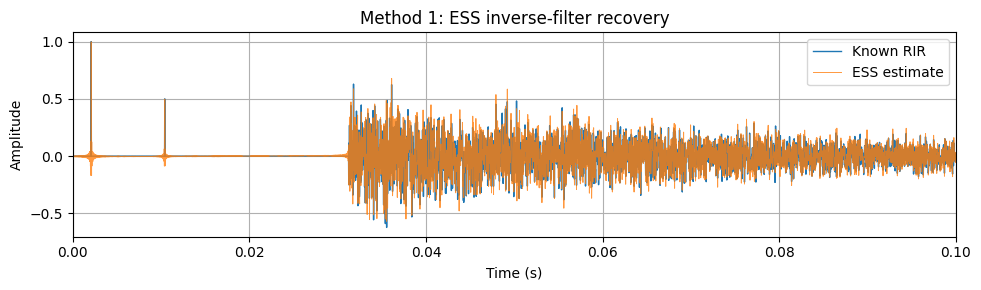

In [ ]:
deconvolved_ess = signal.fftconvolve(recording_noisy, inverse_filter, mode="full")

# t = 0 of the measurement chain is at index peak_index (= N-1); the RIR starts there.
estimated_rir_ess = deconvolved_ess[peak_index:peak_index + rir_length]

print("Detected direct-path index:", np.argmax(np.abs(estimated_rir_ess)), "(true if = 100)")

plt.figure(figsize=(10, 3))
plt.plot(rir_time, true_rir, label="Known RIR", linewidth=1)
plt.plot(rir_time, estimated_rir_ess, label="ESS estimate", linewidth=0.7, alpha=0.8)
plt.xlim(0,0.1)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Method 1: ESS inverse-filter recovery")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Method 2 — Frequency-domain deconvolution

For this method we transform the recorded signal and reference sweep into the frequency domain using the Fast Fourier Transform (FFT), divide their spectra to estimate the room response, and then transform the result back into time. Regularization helps prevent noise or very small spectral values from being excessively amplified.

Equation:

$$ \hat H(f) = \frac{Y(f)X^*(f)}{|X(f)|^2+\alpha}, \quad \hat h[n] = {F}^{-1}\{\hat H(f)\} $$

where:
- $X(f)$ = The Discrete Fourier Transform (DFT) of the input sweep signal ($ESS$) and (*) denotes complex conjugation
- $Y(f)$ = The DFT of the simulated recording
- $\hat H(f)$ = regularized frequency response estimate of the room
- $\hat h[n]$ = The recovered room impulse response estimate converted back into the time-domain using the Inverse Fast Fourier Transform (IFFT)
- $\alpha$ = A small positive scaling factor added to the denominator to prevent division by zero or division by very small numbers, which would otherwise amplify noise wherever the sweep has little energy (below $f_1$, above $f_2$)

Note:
- **n_fft**: The Fast Fourier Transform (FFT) length. This must be at least **len(sweep) + len(rir) - 1** to avoid frequency wrap-around (aliasing)


### Participant Cell 5 — Run Method 2: Frequency-domain deconvolution

This alternative estimates the room response in the frequency domain, using regularization to reduce amplification of noise where the sweep has little energy. Compare its result with Method 1 below.

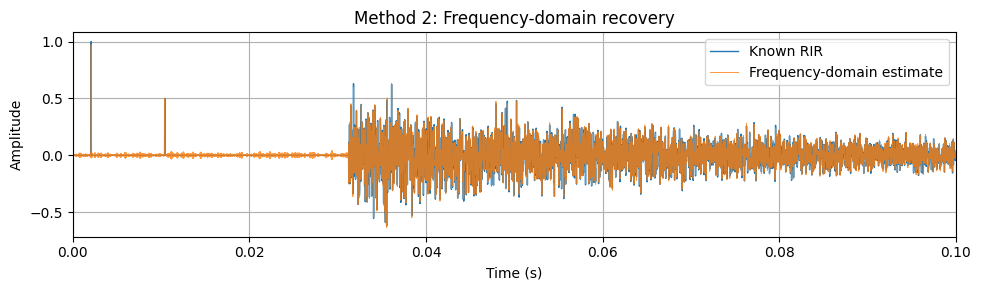

In [ ]:
# Transform the sweep and recording using the same FFT length.
n_fft = len(recording_noisy)
X = np.fft.rfft(ESS, n=n_fft)
Y = np.fft.rfft(recording_noisy, n=n_fft)

alpha = 1e-8 * np.max(np.abs(X)**2)
H_est = Y * np.conj(X) / (np.abs(X)**2 + alpha)
estimated_rir_freq = np.fft.irfft(H_est, n=n_fft)[:rir_length]

plt.figure(figsize=(10, 3))
plt.plot(rir_time, true_rir, label="Known RIR", linewidth=1)
plt.plot(rir_time, estimated_rir_freq, label="Frequency-domain estimate", linewidth=0.7, alpha=0.8)
plt.xlim(0,0.1)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Method 2: Frequency-domain recovery")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


## Participant cell 6 — Compare both estimates

(1) $ \hat h_{\mathrm{ESS}} = y[n] * h_{\mathrm{inv}}[n] $

(2) $ \hat H(f) = \frac{Y(f)X^*(f)}{|X(f)|^2+\alpha} $

Compare both estimates with the known RIR.

This plot overlays the known RIR with the results from the two deconvolution methods. Use it to compare how well each method recovers the direct sound and early reflections.

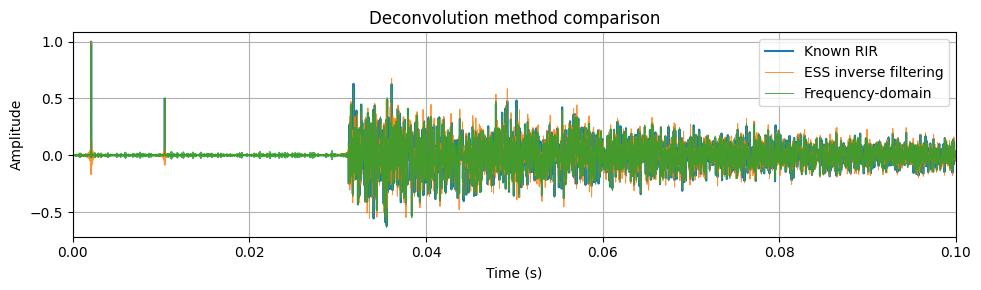

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(rir_time, true_rir, label="Known RIR", linewidth=1.5)
plt.plot(rir_time, estimated_rir_ess, label="ESS inverse filtering", linewidth=0.7, alpha=0.85)
plt.plot(rir_time, estimated_rir_freq, label="Frequency-domain", linewidth=0.7, alpha=0.85)
plt.xlim(0, 0.1)
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.title("Deconvolution method comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 6. Optional: Harmonic Distortion Separation

This is the ESS advantage mentioned in Section 2. A real loudspeaker is not perfectly linear, so we model passing the sweep through a mild asymmetric nonlinearity (producing 2nd and 3rd harmonics) before the room, then deconvolve exactly as before.

The $k$-th harmonic lands at:

$$ \Delta t_k = -\,\frac{T\ln k}{\ln(w_2/w_1)} $$

where $\Delta t_k$ is in seconds relative to the linear IR, i.e. at *negative* time. We simply keep everything from $t=0$ onward and the distortion is gone.

The code cell below contains the nonlinear simulation and the plot of the predicted harmonic locations. It is useful extension material, but it is not required to run the two deconvolution methods above.

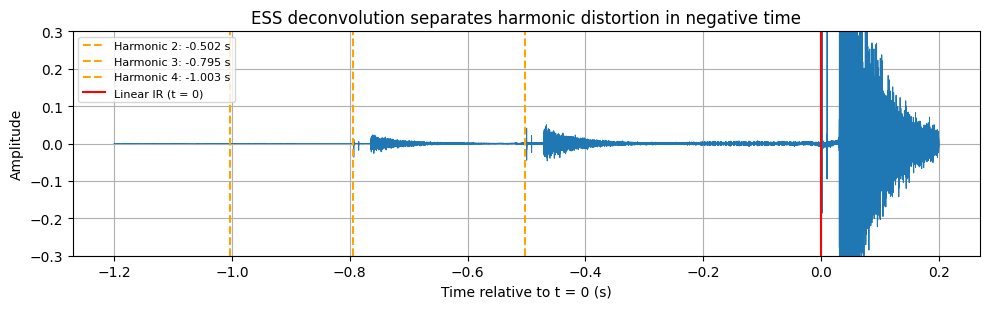

In [ ]:
# Simulate loudspeaker distortion, pass it through the room, then deconvolve.
ESS_distorted = ESS + 0.15 * ESS**2 + 0.15 * ESS**3
dec_dist = signal.fftconvolve(signal.fftconvolve(ESS_distorted, true_rir), inverse_filter)

# Show the negative-time harmonic peaks and the linear response at t = 0.
t_rel = (np.arange(len(dec_dist)) - peak_index) / fs
view = (t_rel > -1.2) & (t_rel < 0.2)

plt.figure(figsize=(10, 3.2))
plt.plot(t_rel[view], dec_dist[view], linewidth=0.7)
for k in (2, 3, 4):
    dt = -T * np.log(k) / np.log(w2 / w1)
    plt.axvline(dt, linestyle="--", color="orange", label=f"Harmonic {k}: {dt:.3f} s")
plt.axvline(0, color="red", label="Linear IR (t = 0)")
plt.ylim(-0.3, 0.3)
plt.xlabel("Time relative to t = 0 (s)")
plt.ylabel("Amplitude")
plt.title("ESS deconvolution separates harmonic distortion in negative time")
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# 7. Optional: From Mono RIR to Simulated B-format SRIR

A spatial measurement is *the same measurement repeated for each microphone channel*. A first-order Ambisonic microphone gives four channels, so we can:

1. **Simulate** a four-channel B-format room response with a shoebox image-source model. Every image source is one plane-wave arrival with a delay, a gain and a direction, encoded into the four channels.
2. **"Record"** the sweep through it (with unknown latency and noise) and **deconvolve all four channels** with the *same* inverse filter.
3. **Trim** at the direct sound, **inspect** where the early energy came from, and **export** a 4-channel WAV.

**Convention (important!):** AmbiX = ACN channel order **[W, Y, Z, X]**, SN3D normalization. Older FuMa material uses order [W, X, Y, Z] and a different W gain; mixing the two up is the most common reason an Ambisonic IR "sounds wrong" in a DAW.

For a plane wave from azimuth $\theta$ (0 = front, +90° = left) and elevation $\phi$:

$$W = 1,\quad Y = \sin\theta\cos\phi,\quad Z = \sin\phi,\quad X = \cos\theta\cos\phi$$

(A real tetrahedral A-format microphone adds a capsule-to-B-format conversion matrix and calibration filters; those are outside this demo.)

## Optional advanced extension — Simulate and recover a four-channel SRIR

The following cells implement the shoebox image-source model, simulate a four-channel recording, and deconvolve the channels. They are included unchanged from the full technical notebook. Expand this section if you want to explore spatial impulse responses; it is not required for the core mono-RIR demonstration.

In [ ]:
# Simulate a shoebox-room B-format RIR using the image-source method.
c = 343.0  # Speed of sound (m/s)

def simulate_bformat_rir(room=(6.0, 5.0, 3.2), src=(1.5, 1.5, 1.6),
                         rcv=(4.0, 3.0, 1.5), absorption=0.3,
                         duration=0.6, fs=48000):
    """Return a (4, samples) RIR in AmbiX channel order [W, Y, Z, X]."""
    L, s, r0 = np.array(room), np.array(src), np.array(rcv)
    beta = np.sqrt(1 - absorption)
    max_distance = c * duration
    orders = [np.arange(-int(np.ceil(max_distance / (2 * l))) - 1,
                        int(np.ceil(max_distance / (2 * l))) + 2) for l in L]
    grids = np.meshgrid(*orders, indexing="ij")
    out = np.zeros((4, int(duration * fs)))
    direct_distance = np.linalg.norm(s - r0)

    # Each parity/grid combination represents one family of image sources.
    for q in np.ndindex(2, 2, 2):
        pos = [(1 - 2*q[i]) * s[i] + 2*L[i] * grids[i] for i in range(3)]
        d = [pos[i] - r0[i] for i in range(3)]
        distance = np.sqrt(sum(axis**2 for axis in d))
        hits = sum(np.abs(grids[i] - q[i]) + np.abs(grids[i]) for i in range(3))
        valid = distance < max_distance
        r, dx, dy, dz, hits = (v[valid] for v in (distance, d[0], d[1], d[2], hits))

        amp = beta**hits * direct_distance / r
        sample = np.round(r * fs / c).astype(int)
        azimuth = np.arctan2(dy, dx)
        elevation = np.arcsin(dz / r)
        # First-order AmbiX / SN3D encoding: W, Y, Z, X.
        channels = (np.ones_like(azimuth),
                    np.sin(azimuth) * np.cos(elevation),
                    np.sin(elevation),
                    np.cos(azimuth) * np.cos(elevation))
        for ch, values in enumerate(channels):
            out[ch] += np.bincount(sample, weights=amp * values,
                                   minlength=out.shape[1])[:out.shape[1]]
    return out

h_true = simulate_bformat_rir(fs=fs)
print("B-format RIR shape (channels, samples):", h_true.shape)

# Expected direct-sound azimuth, measured from receiver toward source.
source_to_receiver = np.array((1.5, 1.5, 1.6)) - np.array((4.0, 3.0, 1.5))
true_direct_az = np.degrees(np.arctan2(source_to_receiver[1], source_to_receiver[0]))
print(f"True direct-sound azimuth: {true_direct_az:.1f}°")

B-format RIR shape (channels, samples): (4, 28800)
True direct-sound azimuth: -149.0°


Direct sound at sample 648 (latency + propagation delay)


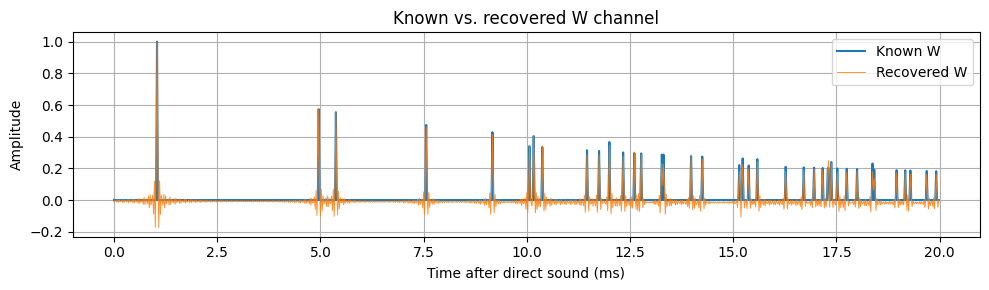

In [ ]:
# Simulate a 4-channel recording with latency and 40 dB SNR, then deconvolve it.
rng = np.random.default_rng(0)
latency = 240
room_with_latency = np.pad(h_true, ((0, 0), (latency, 0)))
rec4 = signal.fftconvolve(ESS[None, :], room_with_latency, axes=1)
rec4 += rng.standard_normal(rec4.shape) * np.sqrt(np.mean(rec4**2)) * 10**(-40 / 20)

dec4 = signal.fftconvolve(rec4, inverse_filter[None, :], axes=1)
ir_all = dec4[:, peak_index:]  # t = 0 of the sweep/inverse-filter pair
arrival = np.argmax(np.abs(ir_all[0, :int(0.05 * fs)]))
pre_roll = 50
start = arrival - pre_roll
ir = ir_all[:, start:start + h_true.shape[1]]
print(f"Direct sound at sample {arrival} (latency + propagation delay)")

# Compare the recovered W channel with the simulated ground truth.
direct = np.argmax(np.abs(h_true[0]))
n_show = int(0.02 * fs)
time_ms = np.arange(n_show) / fs * 1e3
plt.figure(figsize=(10, 3))
plt.plot(time_ms, h_true[0, direct-pre_roll:direct-pre_roll+n_show], label="Known W")
plt.plot(time_ms, ir[0, :n_show], label="Recovered W", linewidth=0.7, alpha=0.85)
plt.xlabel("Time after direct sound (ms)")
plt.ylabel("Amplitude")
plt.title("Known vs. recovered W channel")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Optional advanced extension — Inspect early-arrival directions

This cell estimates the azimuth of early arrivals from the simulated Ambisonic channels. It illustrates the additional directional information available in a spatial recording.

### Where did the early energy come from?

With W (pressure) and X, Y (velocity) we can form a per-sample pseudo-intensity direction, $\theta = \mathrm{atan2}(W\!\cdot\!Y,\; W\!\cdot\!X)$. The first (largest) point is the direct sound and should match the geometry printed above; the later points are early reflections arriving from the walls, floor and ceiling. This is a quick sanity check that the four channels really carry spatial information.

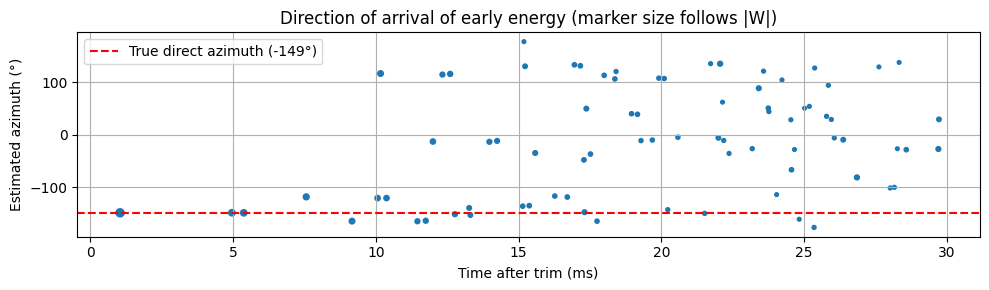

In [ ]:
# Estimate the direction of early arrivals from the B-format channels.
W, Y, Z, X = ir
n_early = int(0.03 * fs)
w, x, y = W[:n_early], X[:n_early], Y[:n_early]
azimuth = np.degrees(np.arctan2(w * y, w * x))
keep = np.abs(w) > 0.1 * np.max(np.abs(w))

plt.figure(figsize=(10, 3))
plt.scatter(np.arange(n_early)[keep] / fs * 1e3, azimuth[keep],
            s=30 * np.abs(w[keep]) / np.max(np.abs(w)) + 4)
plt.axhline(true_direct_az, color="red", linestyle="--",
            label=f"True direct azimuth ({true_direct_az:.0f}°)")
plt.xlabel("Time after trim (ms)")
plt.ylabel("Estimated azimuth (°)")
plt.title("Direction of arrival of early energy (marker size follows |W|)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Optional advanced extension — Listen and export

This final extension creates a virtual cardioid stereo audition and exports the simulated four-channel AmbiX impulse response. Treat the listening example as illustrative rather than as a validated binaural rendering.

### Listen and export

Without an HRTF set, a quick way to audition a B-format IR on headphones is a **virtual cardioid pair** at $\pm 90^\circ$ (a coincident stereo microphone):

$$ s_{\mathrm{card}}(\theta) = \tfrac12\left(W + \cos\theta\, X + \sin\theta\, Y\right) $$

We convolve it with a short dry sound (synthesized here so no download is needed), then export the 4-channel IR as a **32-bit float WAV** (AmbiX). In Reaper, drag the file into ReaVerb (multichannel IR) on a mono track routed to a 4-channel parent, then decode with an AmbiX-compatible plugin (e.g. IEM or SPARTA). Binaural decoding with an HRTF set is a good take-home extension.

In [ ]:
def virtual_cardioid(az_deg, W, Y, X):
    """Horizontal first-order virtual cardioid from AmbiX/SN3D channels."""
    a = np.radians(az_deg)
    return 0.5 * (W + np.cos(a) * X + np.sin(a) * Y)

# Build a left/right virtual cardioid pair at +90° and -90°.
stereo_ir = np.stack((virtual_cardioid(+90, W, Y, X),
                      virtual_cardioid(-90, W, Y, X)))

# Create a short dry transient and convolve it with each ear's response.
rng = np.random.default_rng(1)
n_dry = int(0.25 * fs)
dry = rng.standard_normal(n_dry) * np.exp(-np.arange(n_dry) / (0.03 * fs))
dry /= np.max(np.abs(dry))
wet = np.stack([signal.fftconvolve(dry, h) for h in stereo_ir])

print("Dry sound:")
display(Audio(dry, rate=fs))
print("Through the simulated room (headphones recommended):")
display(Audio(wet, rate=fs))

# Export the four-channel AmbiX impulse response as a 32-bit float WAV.
sf.write("srir_foa_ambix.wav", ir.T.astype(np.float32), fs, subtype="FLOAT")
print("Saved srir_foa_ambix.wav (W, Y, Z, X; AmbiX ACN/SN3D)")

Dry sound:


Through the simulated room (headphones recommended):


Saved srir_foa_ambix.wav (W, Y, Z, X; AmbiX ACN/SN3D)
